# Preprocessing notebook: audio and speech evidence, Hazem and Ebtihal pair (Phase 2)

Project: Smart Voicemail Router. Branch: `team/audio-speech`.

Contents: 1 Canonical hashes. 2 Transcript cleaning. 3 Audio. 4 Split. 5 Excluded files. 6 Summary.

The canonical files are read-only; every fix lands in derived files outside the repo. Cleaning is re-run live and compared with the saved derived files. Audio checks are idempotent: missing or invalid WAVs are converted, the rest are only verified.

In [1]:
import json
import random
import subprocess
import unicodedata
import wave
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
import pandas as pd
from IPython.display import Image

REPO = Path("/home/hatch/workspace/ai-customer-support/smart-voicemail-router")
DATASET = Path("/home/hatch/workspace/ai-customer-support/dataset")
PREP = DATASET / "preprocessed"
CSV_DIR = Path("/home/hatch/workspace/user/files")
EXTRACTED = DATASET / "extracted"
AUDIO_16K = PREP / "audio_16k"
CANONICAL_CSV = CSV_DIR / "transcripts_flagged_14_4zfb.csv"
INVENTORY_CSV = CSV_DIR / "inventory_clean_13_825a.csv"
CLEAN_CSV = PREP / "transcripts_clean.csv"
MANIFEST_CSV = PREP / "disposition_manifest.csv"
SEED = 42
TARGETS = {"train": 0.70, "val": 0.20, "test": 0.10}
RESULTS = {}


def save_bar(values, title, xlabel, ylabel, path):
    fig = Figure()
    FigureCanvasAgg(fig)
    ax = fig.add_subplot(111)
    ax.bar(list(values.keys()), list(values.values()))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    return path


def wav_path(dataset_file):
    basename = Path(dataset_file.replace("\\", "/")).name
    return AUDIO_16K / (basename + ".wav")


def source_path(dataset_file):
    return EXTRACTED / unicodedata.normalize("NFD", dataset_file.replace("\\", "/"))


def clean(transcripts, inventory):
    df = transcripts.copy()
    df["dup_text_size"] = df["text_norm"].map(df["text_norm"].value_counts()).astype(int)
    df["prompt"] = df["prompt"].fillna("")
    df.loc[df["prompt"] == "", "prompt"] = "none"
    inv = inventory.copy()
    inv["silence_pct"] = inv["silence_pct"].astype(float)
    inv["snr_db"] = inv["snr_db"].astype(float)
    inv["clip_pct"] = inv["clip_pct"].astype(float)
    df = df.merge(inv[["file", "silence_pct", "snr_db", "clip_pct"]], on="file", how="left")
    if df[["silence_pct", "snr_db", "clip_pct"]].isna().any().any():
        missing = df[df["silence_pct"].isna()]["file"].tolist()
        raise ValueError(f"transcript rows missing inventory measures: {missing}")
    needs_review = df["needs_review"].str.strip().str.lower() == "true"
    silence = df["silence_pct"] > 50
    low_snr = df["snr_db"] < 10
    clipping = df["clip_pct"] > 0
    df["prep_status"] = "train_ready"
    df.loc[needs_review | silence | low_snr, "prep_status"] = "quarantine"

    def reasons(row):
        flags = []
        if row["_needs_review"]:
            flags.append("needs_review")
        if row["_silence"]:
            flags.append("silence_gt_50pct")
        if row["_low_snr"]:
            flags.append("snr_lt_10db")
        if row["_clipping"]:
            flags.append("clipping")
        return ";".join(flags)

    df["_needs_review"] = needs_review
    df["_silence"] = silence
    df["_low_snr"] = low_snr
    df["_clipping"] = clipping
    df["prep_reason"] = df.apply(reasons, axis=1)
    df = df.drop(columns=["_needs_review", "_silence", "_low_snr", "_clipping",
                          "silence_pct", "snr_db", "clip_pct"])
    return df[list(transcripts.columns) + ["prep_status", "prep_reason"]]


def build_manifest(clean_df, inventory):
    status = clean_df.set_index("file")["prep_status"]
    reason = clean_df.set_index("file")["prep_reason"]
    rows = []
    for _, inv_row in inventory.iterrows():
        f = inv_row["file"]
        if f in status.index:
            rows.append({"file": f, "prep_status": status[f], "prep_reason": reason[f]})
        else:
            rows.append({
                "file": f,
                "prep_status": "excluded",
                "prep_reason": inv_row["exclude_reason"] or "excluded_no_reason",
            })
    return pd.DataFrame(rows, columns=["file", "prep_status", "prep_reason"])


def compute_split(clean_df, inventory):
    inv = inventory.copy()
    inv["duration_s"] = inv["duration_s"].astype(float)
    dur = dict(zip(inv["file"], inv["duration_s"]))
    fmt = dict(zip(inv["file"], inv["ext"]))
    train_ready = clean_df[clean_df["prep_status"] == "train_ready"]
    total = len(train_ready)
    quartiles = train_ready["file"].map(dur).quantile([0.25, 0.5, 0.75])
    q1, q2, q3 = quartiles[0.25], quartiles[0.5], quartiles[0.75]

    def quartile(d):
        if d <= q1:
            return 0
        if d <= q2:
            return 1
        if d <= q3:
            return 2
        return 3

    groups = defaultdict(list)
    for _, row in train_ready.iterrows():
        groups[row["text_norm"]].append(row["file"])
    strata = defaultdict(list)
    for norm, files in groups.items():
        ds = sorted(dur[f] for f in files)
        median_d = ds[len(ds) // 2]
        modal_fmt = Counter(fmt[f] for f in files).most_common(1)[0][0]
        strata[(quartile(median_d), modal_fmt)].append(files)
    target_counts = {s: round(TARGETS[s] * total) for s in TARGETS}
    counts = Counter()
    splits = {s: [] for s in TARGETS}
    rng = random.Random(SEED)
    for stratum in sorted(strata):
        members = sorted(strata[stratum], key=lambda fs: fs[0])
        rng.shuffle(members)
        for files in members:
            side = min(TARGETS, key=lambda s: counts[s] / max(target_counts[s], 1))
            splits[side].extend(files)
            counts[side] += len(files)
    return {s: sorted(v) for s, v in splits.items()}


RECOVERABLE_REASONS = {"low_snr", "clipped", "too_long", "mostly_silence"}


def excluded_disposition(inventory):
    ex = inventory[inventory["exclude_reason"].fillna("") != ""]
    reasons = Counter(ex["exclude_reason"])
    recoverable = sum(n for r, n in reasons.items() if r in RECOVERABLE_REASONS)
    return {
        "total": int(len(ex)),
        "reasons": dict(sorted(reasons.items())),
        "recoverable": int(recoverable),
        "permanently_unusable": int(len(ex) - recoverable),
        "recoverable_reasons": sorted(RECOVERABLE_REASONS),
    }

## 1. Canonical hashes

The four canonical input files were hashed before preprocessing. This cell re-checks them now; all four must read OK, or the run stops.

In [2]:
proc = subprocess.run(
    ["sha256sum", "-c", str(PREP / "run_log_hashes.txt")],
    capture_output=True, text=True,
)
print(proc.stdout, end="")
if proc.stderr:
    print(proc.stderr, end="")
ok_count = proc.stdout.count(": OK")
print(f"Files OK: {ok_count} of 4")
assert proc.returncode == 0, "sha256sum -c failed"
assert ok_count == 4, "expected all 4 canonical files to read OK"
print("Canonical files are byte-identical to the pre-run hashes.")
RESULTS["canonical_hashes_ok"] = ok_count

/home/hatch/workspace/user/files/transcripts_flagged_14_4zfb.csv: OK
/home/hatch/workspace/user/files/inventory_clean_13_825a.csv: OK
/home/hatch/workspace/user/files/stt_results_12_d6z5.csv: OK
/home/hatch/workspace/user/files/sample_11_laqj.csv: OK
Files OK: 4 of 4
Canonical files are byte-identical to the pre-run hashes.


## 2. Transcript cleaning

Repeats the cleaning logic inline: recompute `dup_text_size` from `text_norm` groups, normalize empty prompts to `none`, merge the inventory acoustic measures, assign `prep_status` and `prep_reason`. The re-run output is compared cell by cell with the saved derived files. Any difference fails the cell.

Re-run output matches the saved derived files exactly.
Derived file columns (13): ['file', 'text', 'model', 'max_no_speech_prob', 'min_avg_logprob', 'prompt', 'error', 'text_norm', 'review_reasons', 'needs_review', 'dup_text_size', 'prep_status', 'prep_reason']
Disposition (transcript rows):


,rows
prep_status,
train_ready,5881
quarantine,143


Disposition (all files, manifest):


,files
prep_status,
train_ready,5881
excluded,498
quarantine,143


Quarantine reason counts (transcript rows):


,rows
prep_reason,
needs_review,128
silence_gt_50pct,7
needs_review;clipping,5
silence_gt_50pct;clipping,3


dup_text_size rows changed vs canonical: 3
Canonical rows with empty prompt: 581
Derived rows reading 'none' for prompt: 6024 of 6024
The dup fix is proposed, pending the user's review; the canonical file is untouched.


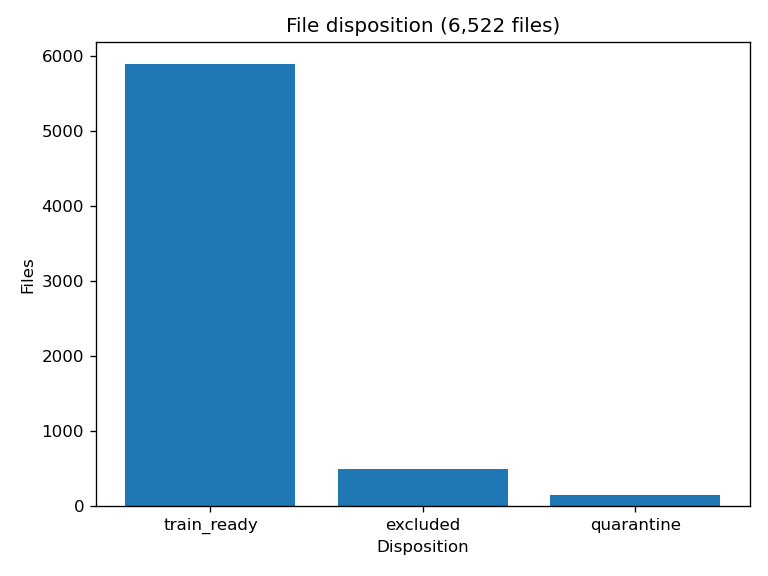

In [3]:
transcripts = pd.read_csv(CANONICAL_CSV, dtype=str, encoding="utf-8-sig")
inventory = pd.read_csv(INVENTORY_CSV, dtype=str, encoding="utf-8-sig")
clean_df = clean(transcripts, inventory)
manifest = build_manifest(clean_df, inventory)
saved_clean = pd.read_csv(CLEAN_CSV, dtype=str, encoding="utf-8")
saved_manifest = pd.read_csv(MANIFEST_CSV, dtype=str, encoding="utf-8")
pd.testing.assert_frame_equal(
    clean_df.fillna("").astype(str), saved_clean.fillna("").astype(str), check_dtype=False)
pd.testing.assert_frame_equal(
    manifest.fillna("").astype(str), saved_manifest.fillna("").astype(str), check_dtype=False)
print("Re-run output matches the saved derived files exactly.")
print(f"Derived file columns ({len(clean_df.columns)}): {list(clean_df.columns)}")
print("Disposition (transcript rows):")
display(pd.DataFrame(clean_df["prep_status"].value_counts()).rename(columns={"count": "rows"}))
print("Disposition (all files, manifest):")
display(pd.DataFrame(manifest["prep_status"].value_counts()).rename(columns={"count": "files"}))
print("Quarantine reason counts (transcript rows):")
display(pd.DataFrame(clean_df.loc[clean_df["prep_status"] == "quarantine", "prep_reason"]
                     .value_counts()).rename(columns={"count": "rows"}))
changed = (transcripts["dup_text_size"].astype(int)
           != clean_df["dup_text_size"].astype(int))
print(f"dup_text_size rows changed vs canonical: {int(changed.sum())}")
assert int(changed.sum()) == 3
canon_empty_prompt = int(((transcripts["prompt"].fillna("") == "")).sum())
print(f"Canonical rows with empty prompt: {canon_empty_prompt}")
print(f"Derived rows reading 'none' for prompt: {int((clean_df['prompt'] == 'none').sum())} of {len(clean_df)}")
assert canon_empty_prompt == 581
assert int((clean_df["prompt"] == "none").sum()) == len(clean_df)
print("The dup fix is proposed, pending the user's review; the canonical file is untouched.")
status_counts = manifest["prep_status"].value_counts()
p = save_bar(dict(status_counts), "File disposition (6,522 files)", "Disposition", "Files",
             REPO / "preprocessing" / "figures" / "disposition_bar.png")
display(Image(filename=str(p)))
RESULTS["transcripts"] = {
    "rows": len(clean_df),
    "train_ready": int((clean_df["prep_status"] == "train_ready").sum()),
    "quarantine": int((clean_df["prep_status"] == "quarantine").sum()),
    "dup_fixed_rows": int(changed.sum()),
    "prompt_normalized_rows": canon_empty_prompt,
}

## 3. Audio

Train-ready files were standardized to 16 kHz mono WAVs by the pipeline. This cell verifies the existing WAVs (header rate and channels, frame count against the decode record) and converts only missing or invalid files. It then checks a random sample of 20 WAVs with ffprobe and loads the decode record for the drift table.

In [4]:
decode = json.loads((PREP / "audio_decode.json").read_text(encoding="utf-8"))
recs = decode["files"]
train_ready = manifest[manifest["prep_status"] == "train_ready"]["file"].tolist()
print(f"Train-ready files: {len(train_ready)}")
print(f"Decode records: {len(recs)}")
missing, invalid = [], []
for f in train_ready:
    w = wav_path(f)
    if not w.exists():
        missing.append(f)
        continue
    try:
        with wave.open(str(w), "rb") as wf:
            if (wf.getframerate() != 16000 or wf.getnchannels() != 1
                    or wf.getnframes() != recs[f]["samples"]):
                invalid.append(f)
    except (wave.Error, KeyError):
        invalid.append(f)
print(f"Missing WAVs: {len(missing)}, invalid WAVs: {len(invalid)}")
for f in missing + invalid:
    src = source_path(f)
    out = wav_path(f)
    subprocess.run(["ffmpeg", "-v", "error", "-y", "-i", str(src),
                    "-ac", "1", "-ar", "16000", str(out)], check=True)
    print(f"converted: {f}")
print(f"Converted in this run: {len(missing) + len(invalid)}")
assert len(missing) == 0 and len(invalid) == 0
wav_count = len(list(AUDIO_16K.glob("*.wav")))
print(f"WAV files on disk: {wav_count}")
assert wav_count == len(train_ready)
rng = random.Random(42)
sample = rng.sample(train_ready, 20)
for f in sample:
    proc = subprocess.run(["ffprobe", "-v", "error", "-show_entries",
                           "stream=sample_rate,channels", "-of", "csv=p=0",
                           str(wav_path(f))], capture_output=True, text=True)
    sr, ch = proc.stdout.strip().split(",")
    assert int(sr) == 16000 and int(ch) == 1, f
print("ffprobe sample: 20 of 20 WAVs are 16 kHz mono")
total_s = sum(r["duration_s"] for r in recs.values())
print(f"Total standardized duration: {total_s:.2f} s = {total_s / 3600:.2f} h")
hashes = [r["pcm_sha256"] for r in recs.values()]
print(f"Unique decoded PCM hashes: {len(set(hashes))} of {len(hashes)} "
      f"(audio duplicates: {len(hashes) - len(set(hashes))})")
assert len(set(hashes)) == len(hashes)
print(f"Decoded-vs-inventory drift: {decode['drift_vs_inventory']}")
RESULTS["audio"] = {
    "standardized_files": wav_count,
    "total_duration_h": round(total_s / 3600, 2),
    "duplicate_audio": len(hashes) - len(set(hashes)),
    "drift_gt_0.1s": decode["drift_vs_inventory"]["gt_0.1s"],
    "max_drift_s": decode["drift_vs_inventory"]["max_drift_s"],
}

Train-ready files: 5881
Decode records: 5881


Missing WAVs: 0, invalid WAVs: 0
Converted in this run: 0
WAV files on disk: 5881


ffprobe sample: 20 of 20 WAVs are 16 kHz mono
Total standardized duration: 41093.33 s = 11.41 h
Unique decoded PCM hashes: 5881 of 5881 (audio duplicates: 0)
Decoded-vs-inventory drift: {'by_format': {'.aac': 79, '.m4a': 3}, 'gt_0.1s': 82, 'max_drift_s': 0.487}


## 4. Split

Final split on the train-ready set, 70/20/10, seed 42. Whole `text_norm` groups stay on one side. With 5,881 train-ready rows, a 20% validation set (about 1,176 rows) gives reliable model selection, while training still keeps about 4,100 rows and the test set stays at 10% (about 588 rows). This supersedes the old 4704/589/588 split and split_dev.json.

In [5]:
splits = compute_split(clean_df, inventory)
for side, files in splits.items():
    (PREP / f"split_{side}.json").write_text(json.dumps(files, indent=1, sort_keys=True))
    print(f"split {side}: {len(files)} files")
old_dev = PREP / "split_dev.json"
if old_dev.exists():
    old_dev.unlink()
    print("Removed the superseded split_dev.json.")
sizes = {k: len(v) for k, v in splits.items()}
total = sum(sizes.values())
print(f"Split sizes: train {sizes['train']}, val {sizes['val']}, test {sizes['test']}, total {total}")
norm_of = dict(zip(clean_df["file"], clean_df["text_norm"]))
ready = set(clean_df.loc[clean_df["prep_status"] == "train_ready", "file"])
all_assigned = set().union(*[set(v) for v in splits.values()])
print(f"Covers the train-ready set exactly: {all_assigned == ready}")
group_sides = defaultdict(set)
for split, members in splits.items():
    for f in members:
        group_sides[norm_of[f]].add(split)
leaked = sum(1 for s in group_sides.values() if len(s) > 1)
print(f"Leaked text_norm groups: {leaked}")
shares = pd.DataFrame([
    ["train", sizes["train"], round(100 * sizes["train"] / total, 1)],
    ["val", sizes["val"], round(100 * sizes["val"] / total, 1)],
    ["test", sizes["test"], round(100 * sizes["test"] / total, 1)],
], columns=["split", "files", "share_pct"])
display(shares)
assert total == len(ready) == 5881
assert leaked == 0
assert all_assigned == ready
for s, share in TARGETS.items():
    assert abs(sizes[s] / total - share) < 0.02, s
print("Files: split_train.json, split_val.json, split_test.json (outside the repo).")
RESULTS["split"] = {**sizes, "leaked_groups": leaked}

split train: 4117 files
split val: 1176 files
split test: 588 files
Split sizes: train 4117, val 1176, test 588, total 5881
Covers the train-ready set exactly: True
Leaked text_norm groups: 0


,split,files,share_pct
0,train,4117,70.0
1,val,1176,20.0
2,test,588,10.0


Files: split_train.json, split_val.json, split_test.json (outside the repo).


## 5. Excluded files

The 498 excluded files stay excluded. This cell loads the saved disposition and cross-checks the reason counts against the inventory, live.

In [6]:
ex = json.loads((PREP / "excluded_disposition.json").read_text(encoding="utf-8"))
print(f"Excluded total: {ex['total']}")
display(pd.DataFrame(sorted(ex["reasons"].items()), columns=["reason", "files"]))
print(f"Recoverable in principle: {ex['recoverable']} ({ex['recoverable_reasons']})")
print(f"Permanently unusable: {ex['permanently_unusable']}")
ex_rows = inventory[inventory["exclude_reason"].fillna("") != ""]
inv_ex = Counter(ex_rows["exclude_reason"])
print(f"Inventory exclude reasons, counted live: {dict(sorted(inv_ex.items()))}")
assert ex["total"] == 498
assert sum(ex["reasons"].values()) == 498
assert dict(sorted(inv_ex.items())) == dict(sorted(ex["reasons"].items()))
assert ex["recoverable"] == 26
assert ex["permanently_unusable"] == 472
print("Re-included: none. Rescue of the 26 recoverable files is a team decision.")
RESULTS["excluded"] = {"total": ex["total"], "recoverable": ex["recoverable"],
                       "permanently_unusable": ex["permanently_unusable"]}

Excluded total: 498


,reason,files
0,clipped,6
1,duplicate,470
2,low_snr,18
3,mostly_silence,1
4,too_long,1
5,too_short,2


Recoverable in principle: 26 (['clipped', 'low_snr', 'mostly_silence', 'too_long'])
Permanently unusable: 472
Inventory exclude reasons, counted live: {'clipped': 6, 'duplicate': 470, 'low_snr': 18, 'mostly_silence': 1, 'too_long': 1, 'too_short': 2}
Re-included: none. Rescue of the 26 recoverable files is a team decision.


## 6. Summary

Headline numbers, recomputed in the cells above. The dup fix stays proposed until the user confirms it. The split freeze, the rights and consent boundary, the annotation protocol, and the 26 recoverable excluded files are open decisions for the user and the team.

In [7]:
print(json.dumps(RESULTS, indent=2, ensure_ascii=False))

{
  "canonical_hashes_ok": 4,
  "transcripts": {
    "rows": 6024,
    "train_ready": 5881,
    "quarantine": 143,
    "dup_fixed_rows": 3,
    "prompt_normalized_rows": 581
  },
  "audio": {
    "standardized_files": 5881,
    "total_duration_h": 11.41,
    "duplicate_audio": 0,
    "drift_gt_0.1s": 82,
    "max_drift_s": 0.487
  },
  "split": {
    "train": 4117,
    "val": 1176,
    "test": 588,
    "leaked_groups": 0
  },
  "excluded": {
    "total": 498,
    "recoverable": 26,
    "permanently_unusable": 472
  }
}
